# 12 - Codility 1: iterations, arrays, complexity, counting, prefix sums

**Source:** *Codility Lessons* chapters 1-5 (Iterations, Arrays, Time complexity, Counting elements, Prefix sums).

The PDF was written for **Python 2**. Every snippet here is translated to Python 3 and *tested*:

| Python 2 in the PDF | Python 3 |
|---|---|
| `print i`, `print '*',` | `print(i)`, `print('*', end=' ')` |
| `xrange(n)` | `range(n)` (already lazy) |
| `x / y` on ints (floor) | `x // y` (`/` is always true division) |
| `range()` returns a list | `range()` is a lazy sequence; `list(range(n))` if you need a list |

**How to use this notebook:** read the idea -> run the cell -> then do the matching functions in
`codility/practice_01_basics.py` and `codility/practice_02_counting_prefix_sorting.py` and check them with `pytest`.

Practical Codility advice that applies to everything: (1) read the constraints - they tell you the target complexity;
(2) write a brute-force oracle first and compare on random small inputs; (3) think about edge cases: empty,
single element, all equal, negatives, maximum sizes.

## 1. Iterations

In [1]:
n = 5
factorial = 1
for i in range(1, n + 1):
    factorial *= i
print(factorial)

# triangle of asterisks
n = 4
for i in range(1, n + 1):
    for j in range(i):
        print("*", end=" ")
    print()

120
* 
* * 
* * * 
* * * * 


In [2]:
# The "clever idiom" the PDF avoids: string repetition. Upside-down symmetrical triangle:
n = 4
for i in range(n, 0, -1):
    print(" " * (2 * (n - i)) + "* " * (2 * i - 1))

* * * * * * * 
  * * * * * 
    * * * 
      * 


### `while` loops: unknown number of steps

In [3]:
def count_digits(n):
    result = 0
    while n > 0:
        n //= 10          # integer division! In Python 3 `n / 10` would give a float
        result += 1
    return result

assert [count_digits(x) for x in (1, 9, 10, 12345, 10**9)] == [1, 1, 2, 5, 10]
assert count_digits(0) == 0       # pitfall: 0 has one digit but the loop reports 0

def fibonacci_up_to(n):
    a, b = 0, 1
    out = []
    while a <= n:
        out.append(a)
        a, b = b, a + b       # tuple assignment replaces the temp variable `c`
    return out

print(fibonacci_up_to(100))

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89]


### Looping over collections
* `for x in list` - in order; `for x in set` - arbitrary order; `for k in dict` - keys (insertion-ordered since 3.7);
* `enumerate(seq)` for index+value, `zip(a, b)` for parallel iteration, `reversed(seq)`, `sorted(seq)`.

In [4]:
days = {"mon": "Monday", "tue": "Tuesday", "wed": "Wednesday"}
for key, name in days.items():
    print(key, "stands for", name)
for i, (key, name) in enumerate(days.items(), start=1):
    print(i, key, name)

mon stands for Monday
tue stands for Tuesday
wed stands for Wednesday
1 mon Monday
2 tue Tuesday
3 wed Wednesday


## 2. Arrays (Python lists)
`[0] * 365` creates 365 zeros; indexes start at 0; `len(A)`; `A[-1]` is the last element.
Operations: concatenation `+`, repetition `*`, membership `in` (O(n) for lists!), slicing `A[i:j]` (a **copy**, O(j-i)).

In [5]:
def negative(temperatures):
    return sum(1 for t in temperatures if t < 0)

print(negative([3, -1, -5, 0, 7, -2]))

def reverse_in_place(A):
    n = len(A)
    for i in range(n // 2):
        k = n - i - 1
        A[i], A[k] = A[k], A[i]
    return A

A = [1, 2, 3, 4, 5]
assert reverse_in_place(A) == [5, 4, 3, 2, 1]
assert A == [5, 4, 3, 2, 1]                      # mutated: it is in place!
# Idioms: A.reverse() (in place, returns None!), reversed(A) (iterator), A[::-1] (new list)
B = [1, 2, 3]
assert B.reverse() is None and B == [3, 2, 1]
assert list(reversed(B)) == [1, 2, 3] and B[::-1] == [1, 2, 3]

3


### Classic list pitfalls
1. **Aliasing:** `B = A` does not copy. Use `A.copy()`, `A[:]`, `list(A)`; for nested lists `copy.deepcopy`.
2. **`[[0] * m] * n`** creates `n` references to the **same** row. Build matrices with a comprehension.
3. Codility functions should usually **not mutate** their input unless allowed - sort a copy: `sorted(A)`.
4. `A.sort()` and `A.reverse()` return `None`.
5. Negative indices wrap; slices never raise `IndexError`.

In [6]:
grid_bad = [[0] * 3] * 2
grid_bad[0][0] = 9
print(grid_bad)                                    # both rows changed!
grid_ok = [[0] * 3 for _ in range(2)]
grid_ok[0][0] = 9
print(grid_ok)

[[9, 0, 0], [9, 0, 0]]
[[9, 0, 0], [0, 0, 0]]


## 3. Time complexity
Count the **dominant operation** as a function of the input size and drop constants and lower-order terms.

| complexity | example |
|---|---|
| O(1) | arithmetic, `A[i]`, `dict[key]` |
| O(log n) | halving the problem: binary search, `while n > 1: n //= 2` |
| O(n) | one pass over the data |
| O(n log n) | sorting, divide & conquer |
| O(n^2) | two nested loops over the data |
| O(2^n), O(n!) | subsets, permutations - only for n up to ~20 / ~10 |

**Rules of thumb for the time limit** (about 10^8 simple operations per second in C-like languages; **Python is
30-100x slower**, so in Python aim for <= ~10^7 elementary steps per second):
n <= 10^6 -> O(n) or O(n log n); n <= 10^4 -> O(n^2); n <= 500 -> O(n^3).

In [7]:
def dominant(n):
    result = 0
    for i in range(n):
        result += 1                       # executed n times -> O(n)
    return result

def logarithmic(n):
    result = 0
    while n > 1:
        n //= 2                           # halved each step -> O(log n)
        result += 1
    return result

def linear(n, A):
    for i in range(n):
        if A[i] == 0:
            return 0                      # best case O(1), but we analyse the WORST case: O(n)
    return 1

def quadratic(n):
    result = 0
    for i in range(n):
        for j in range(i, n):
            result += 1
    return result

assert dominant(10) == 10 and logarithmic(1024) == 10 and quadratic(10) == 10 * 11 // 2
assert linear(3, [1, 2, 3]) == 1

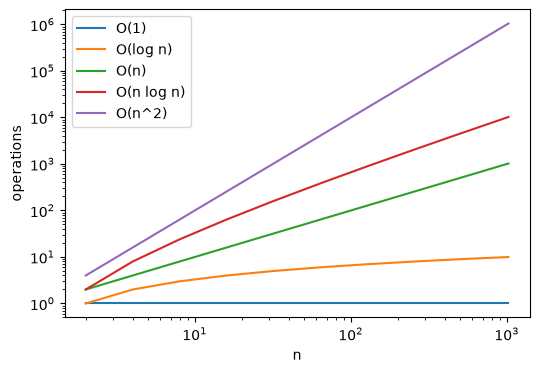

In [8]:
# Empirically: count operations, then plot how they grow
import math
import matplotlib.pyplot as plt

ns = [2**k for k in range(1, 11)]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ns, [1] * len(ns), label="O(1)")
ax.plot(ns, [math.log2(n) for n in ns], label="O(log n)")
ax.plot(ns, ns, label="O(n)")
ax.plot(ns, [n * math.log2(n) for n in ns], label="O(n log n)")
ax.plot(ns, [n * n for n in ns], label="O(n^2)")
ax.set_yscale("log"); ax.set_xscale("log"); ax.set_xlabel("n"); ax.set_ylabel("operations")
ax.legend(); plt.show()

### The 1 + 2 + ... + n example: three complexities, same answer

In [9]:
import timeit

def slow_solution(n):          # O(n^2)
    result = 0
    for i in range(n):
        for j in range(i + 1):
            result += 1
    return result

def fast_solution(n):          # O(n)
    result = 0
    for i in range(n):
        result += i + 1
    return result

def model_solution(n):         # O(1)  -  Gauss
    return n * (n + 1) // 2

n = 1500
assert slow_solution(n) == fast_solution(n) == model_solution(n)
for f in (slow_solution, fast_solution, model_solution):
    print(f"{f.__name__:15} {min(timeit.repeat(lambda: f(n), number=3, repeat=3)) / 3 * 1e3:10.4f} ms")

slow_solution      23.4200 ms
fast_solution       0.0464 ms
model_solution      0.0001 ms


**Space complexity** counts the extra memory: O(1) for a fixed number of variables, O(n) if you allocate an array of
size n (also the recursion stack: Python's default recursion limit is ~1000 - `sys.getrecursionlimit()`; prefer
iteration for deep recursion).

**Python-specific costs you must know:** `x in list` O(n) but `x in set/dict` O(1) average; `list.insert(0, x)` /
`pop(0)` O(n) (use `collections.deque`); `list.append`/`pop()` amortised O(1); `sorted` O(n log n); string `+=` in a
loop can be O(n^2); slicing copies; `len`, indexing O(1).

## 4. Counting elements
If all values are in `0..m`, use the value as an **index** of a counter array: O(n + m) time and O(m) memory.
Python also has `collections.Counter` (a dict) when `m` is huge or values are not integers.

In [10]:
from collections import Counter

def counting(A, m):
    count = [0] * (m + 1)
    for a in A:
        count[a] += 1
    return count

A = [0, 0, 4, 2, 4, 5]
print(counting(A, 5), Counter(A))

[2, 0, 1, 0, 2, 1] Counter({0: 2, 4: 2, 2: 1, 5: 1})


### Swap-the-elements (PDF 4.1)
Is there one `a in A`, `b in B` such that swapping them makes `sum(A) == sum(B)`?
After the swap `sum_A + (b - a) == sum_B - (b - a)` -> `a = b - d/2` with `d = sum_B - sum_A`. So `d` must be even and
`b - d/2` must be present in A (check it with the counters, in O(1)).

In [11]:
def swap_slow(A, B, m):                 # O(n^2) - tries all pairs
    sum_a, sum_b = sum(A), sum(B)
    for a in A:
        for b in B:
            change = b - a
            if sum_a + change == sum_b - change:
                return True
    return False

def swap_fast(A, B, m):                 # O(n + m)
    d = sum(B) - sum(A)
    if d % 2 == 1:                      # Python's % is non-negative for a positive divisor: -3 % 2 == 1
        return False
    d //= 2
    count = counting(A, m)
    return any(0 <= b - d <= m and count[b - d] > 0 for b in B)

import random
rng = random.Random(1)
for _ in range(2000):
    m = rng.randint(1, 8)
    n = rng.randint(1, 5)
    A = [rng.randint(0, m) for _ in range(n)]
    B = [rng.randint(0, m) for _ in range(n)]
    assert swap_slow(A, B, m) == swap_fast(A, B, m), (A, B)
print("swap_fast == swap_slow on 2000 random cases")

swap_fast == swap_slow on 2000 random cases


Pitfall: in C/Java `-3 % 2 == -1`, so `d % 2 == 1` would **miss** negative odd differences. In Python it is
fine - but remember the difference when you read solutions in other languages.

**Practice (`practice_02`)**: `perm_check`, `frog_river_one`, `missing_integer`, `max_counters`.

## 5. Prefix sums
`P[k] = A[0] + ... + A[k-1]` (so `P[0] = 0`, length n+1). Then any slice sum is `sum(A[x..y]) = P[y+1] - P[x]` in O(1).
`itertools.accumulate` builds it in one line.

In [12]:
from itertools import accumulate

def prefix_sums(A):
    P = [0] * (len(A) + 1)
    for k in range(1, len(A) + 1):
        P[k] = P[k - 1] + A[k - 1]
    return P

def count_total(P, x, y):
    return P[y + 1] - P[x]

A = [5, 2, 4, 1, 7]
P = prefix_sums(A)
assert P == [0, *accumulate(A)] == [0, 5, 7, 11, 12, 19]
assert count_total(P, 1, 3) == sum(A[1:4]) == 7
print(P)

[0, 5, 7, 11, 12, 19]


### Mushroom picker (PDF 5.1)
She starts at `k`, makes `m` moves, collects mushrooms on the cells she visits. The best strategy changes direction
**at most once**: go `p` steps one way, come back and continue to the other side (`m - 2p` steps beyond `k`).
Prefix sums give each candidate's total in O(1) -> O(n + m).

In [13]:
def mushrooms(A, k, m):
    n = len(A)
    pref = prefix_sums(A)
    result = 0
    for p in range(min(m, k) + 1):                       # p steps left first, then right
        left_pos = k - p
        right_pos = min(n - 1, max(k, k + m - 2 * p))
        result = max(result, count_total(pref, left_pos, right_pos))
    for p in range(min(m + 1, n - k)):                   # p steps right first, then left
        right_pos = k + p
        left_pos = max(0, min(k, k - (m - 2 * p)))
        result = max(result, count_total(pref, left_pos, right_pos))
    return result

def mushrooms_brute(A, k, m):
    best = 0
    def go(pos, moves, visited):
        nonlocal best
        best = max(best, sum(A[i] for i in visited))
        if moves == 0:
            return
        for nxt in (pos - 1, pos + 1):
            if 0 <= nxt < len(A):
                go(nxt, moves - 1, visited | {nxt})
    go(k, m, {k})
    return best

assert mushrooms([2, 3, 7, 5, 1, 3, 9], 4, 6) == 25
for _ in range(500):
    n = rng.randint(1, 8)
    A = [rng.randint(0, 9) for _ in range(n)]
    k, m = rng.randrange(n), rng.randint(0, 8)
    assert mushrooms(A, k, m) == mushrooms_brute(A, k, m), (A, k, m)
print("mushrooms == brute force on 500 random cases")

mushrooms == brute force on 500 random cases


**Prefix-sum patterns:** range sums; count of elements with property in a range (prefix of 0/1 flags: *genomic range
query*, *count semiprimes*, *passing cars*); 2-D prefix sums for rectangles; difference arrays (the inverse) for
"add v to a range" updates; prefix minima/maxima for *max profit*, *double slice*.

**Practice (`practice_01`, `practice_02`)**: `binary_gap`, `cyclic_rotation`, `odd_occurrences`, `frog_jmp`,
`perm_missing_elem`, `tape_equilibrium`, `passing_cars`, `count_div`, `genomic_range_query`.

## Self-check
1. What is the complexity of `for i in range(n): for j in range(i, n): ...`? Of `for i in range(n): j = 1; while j < n: j *= 2`?
2. Why is `max_counters` naive solution O(N*M) and how does "lazy reset with `base`" fix it?
3. Which Python operations hide O(n) cost inside an O(n) loop (making it O(n^2))?
4. Given `n <= 10^5`, is an O(n^2) Python solution acceptable?